In [2]:
!pip install faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 61.4 MB/s  0:00:00


In [3]:
import torch, torchvision, faiss, numpy, PIL, sklearn
print("OK")
print("torch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

OK
torch: 2.11.0+cu130
GPU available: True


In [6]:
!mkdir -p ~/.kaggle && cp /content/kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d apollo2506/landuse-scene-classification -p /content
!unzip -tq /content/landuse-scene-classification.zip

cp: cannot stat '/content/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/apollo2506/landuse-scene-classification
License(s): CC0-1.0
100% 1.98G/1.98G [00:56<00:00, 37.5MB/s]

No errors detected in compressed data of /content/landuse-scene-classification.zip.


In [7]:
!unzip -q /content/landuse-scene-classification.zip -d /content/ucmerced
!ls /content/ucmerced

images		       label_map.json  test.csv   validation.csv
images_train_test_val  readme.txt      train.csv


In [8]:
!find /content/ucmerced -maxdepth 3 -type d | head -50

/content/ucmerced
/content/ucmerced/images_train_test_val
/content/ucmerced/images_train_test_val/train
/content/ucmerced/images_train_test_val/train/buildings
/content/ucmerced/images_train_test_val/train/beach
/content/ucmerced/images_train_test_val/train/river
/content/ucmerced/images_train_test_val/train/runway
/content/ucmerced/images_train_test_val/train/denseresidential
/content/ucmerced/images_train_test_val/train/mobilehomepark
/content/ucmerced/images_train_test_val/train/harbor
/content/ucmerced/images_train_test_val/train/mediumresidential
/content/ucmerced/images_train_test_val/train/airplane
/content/ucmerced/images_train_test_val/train/freeway
/content/ucmerced/images_train_test_val/train/overpass
/content/ucmerced/images_train_test_val/train/baseballdiamond
/content/ucmerced/images_train_test_val/train/chaparral
/content/ucmerced/images_train_test_val/train/agricultural
/content/ucmerced/images_train_test_val/train/sparseresidential
/content/ucmerced/images_train_test_v

In [9]:
!find /content/ucmerced -maxdepth 3 -type d | head -50

/content/ucmerced
/content/ucmerced/images_train_test_val
/content/ucmerced/images_train_test_val/train
/content/ucmerced/images_train_test_val/train/buildings
/content/ucmerced/images_train_test_val/train/beach
/content/ucmerced/images_train_test_val/train/river
/content/ucmerced/images_train_test_val/train/runway
/content/ucmerced/images_train_test_val/train/denseresidential
/content/ucmerced/images_train_test_val/train/mobilehomepark
/content/ucmerced/images_train_test_val/train/harbor
/content/ucmerced/images_train_test_val/train/mediumresidential
/content/ucmerced/images_train_test_val/train/airplane
/content/ucmerced/images_train_test_val/train/freeway
/content/ucmerced/images_train_test_val/train/overpass
/content/ucmerced/images_train_test_val/train/baseballdiamond
/content/ucmerced/images_train_test_val/train/chaparral
/content/ucmerced/images_train_test_val/train/agricultural
/content/ucmerced/images_train_test_val/train/sparseresidential
/content/ucmerced/images_train_test_v

In [10]:
!for d in $(find /content/ucmerced -maxdepth 2 -type d); do echo "$d: $(find $d -type f | wc -l) files"; done

/content/ucmerced: 21005 files
/content/ucmerced/images_train_test_val: 10500 files
/content/ucmerced/images_train_test_val/train: 7350 files
/content/ucmerced/images_train_test_val/validation: 2100 files
/content/ucmerced/images_train_test_val/test: 1050 files
/content/ucmerced/images: 10500 files
/content/ucmerced/images/buildings: 500 files
/content/ucmerced/images/beach: 500 files
/content/ucmerced/images/river: 500 files
/content/ucmerced/images/runway: 500 files
/content/ucmerced/images/denseresidential: 500 files
/content/ucmerced/images/mobilehomepark: 500 files
/content/ucmerced/images/harbor: 500 files
/content/ucmerced/images/mediumresidential: 500 files
/content/ucmerced/images/airplane: 500 files
/content/ucmerced/images/freeway: 500 files
/content/ucmerced/images/overpass: 500 files
/content/ucmerced/images/baseballdiamond: 500 files
/content/ucmerced/images/chaparral: 500 files
/content/ucmerced/images/agricultural: 500 files
/content/ucmerced/images/sparseresidential: 5

In [11]:
import os
root = "/content/ucmerced/images"
files = sorted(os.listdir(os.path.join(root, "agricultural")))
print(len(files))
print(files[:12])
print(files[-5:])

500
['agricultural_000001.png', 'agricultural_000002.png', 'agricultural_000003.png', 'agricultural_000004.png', 'agricultural_000005.png', 'agricultural_000006.png', 'agricultural_000007.png', 'agricultural_000008.png', 'agricultural_000009.png', 'agricultural_000010.png', 'agricultural_000011.png', 'agricultural_000012.png']
['agricultural_000496.png', 'agricultural_000497.png', 'agricultural_000498.png', 'agricultural_000499.png', 'agricultural_000500.png']


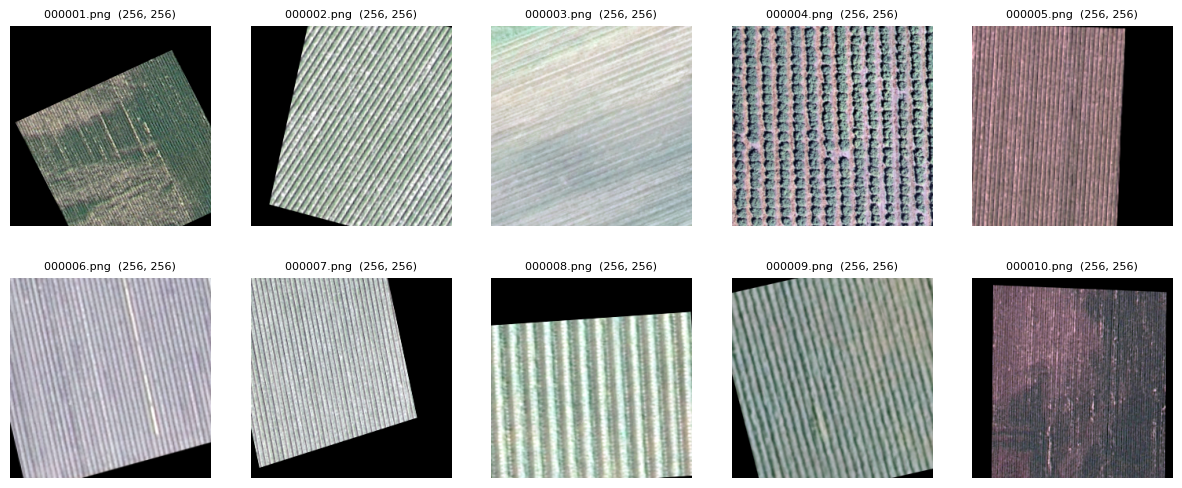

In [12]:
import os
import matplotlib.pyplot as plt
from PIL import Image

folder = "/content/ucmerced/images/agricultural"
files = sorted(os.listdir(folder))[:10]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, f in zip(axes.ravel(), files):
    img = Image.open(os.path.join(folder, f))
    ax.imshow(img)
    ax.set_title(f"{f[-10:]}  {img.size}", fontsize=8)
    ax.axis("off")
plt.show()

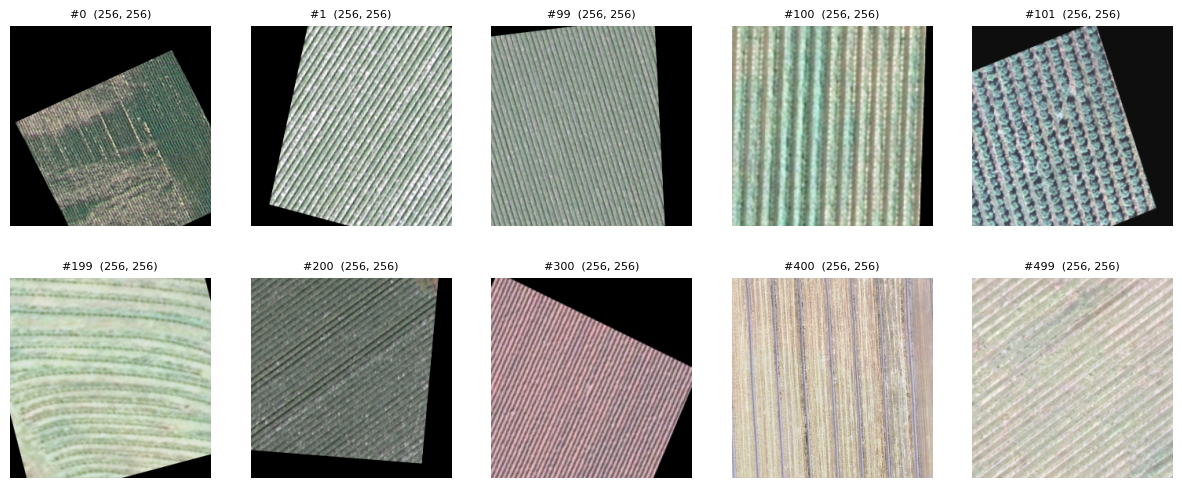

In [13]:
import os
import matplotlib.pyplot as plt
from PIL import Image

folder = "/content/ucmerced/images/agricultural"
files = sorted(os.listdir(folder))
picks = [0, 1, 99, 100, 101, 199, 200, 300, 400, 499]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, i in zip(axes.ravel(), picks):
    img = Image.open(os.path.join(folder, files[i]))
    ax.imshow(img)
    ax.set_title(f"#{i}  {img.size}", fontsize=8)
    ax.axis("off")
plt.show()

In [14]:
import os, numpy as np, torch
from PIL import Image

root = "/content/ucmerced/images"
classes = sorted(os.listdir(root))
paths, labels = [], []
for ci, c in enumerate(classes):
    for f in sorted(os.listdir(os.path.join(root, c))):
        paths.append(os.path.join(root, c, f))
        labels.append(ci)
labels = np.array(labels)

print("Images:", len(paths), "| Classes:", len(classes))
print("Image size:", Image.open(paths[0]).size)

Images: 10500 | Classes: 21
Image size: (256, 256)


In [15]:
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"

tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class DS(Dataset):
    def __len__(self): return len(paths)
    def __getitem__(self, i):
        return tf(Image.open(paths[i]).convert("RGB"))

dl = DataLoader(DS(), batch_size=64, num_workers=2)

model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
model.fc = torch.nn.Identity()   # keep the 2048-d feature vector
model = model.to(device).eval()

feats = []
with torch.no_grad():
    for x in dl:
        feats.append(model(x.to(device)).cpu().numpy())

feats = np.concatenate(feats).astype("float32")
feats /= np.linalg.norm(feats, axis=1, keepdims=True)   # L2-normalize

np.save("/content/feats_resnet50.npy", feats)
np.save("/content/labels.npy", labels)
print("Feature matrix:", feats.shape)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 129MB/s]


Feature matrix: (10500, 2048)


In [16]:
sims = feats @ feats.T
np.fill_diagonal(sims, -1)
nn_sim = sims.max(axis=1)

for t in [0.99, 0.97, 0.95]:
    print(f"Images whose nearest neighbor has similarity > {t}: {(nn_sim > t).sum()}")

Images whose nearest neighbor has similarity > 0.99: 2
Images whose nearest neighbor has similarity > 0.97: 20
Images whose nearest neighbor has similarity > 0.95: 122


In [17]:
import faiss

rng = np.random.default_rng(42)
query_idx, db_idx = [], []
for c in range(len(classes)):
    idx = np.where(labels == c)[0]
    rng.shuffle(idx)
    query_idx += list(idx[:50])    # 50 queries per class = 1,050 total
    db_idx    += list(idx[50:])    # 450 per class = 9,450 in database

query_idx, db_idx = np.array(query_idx), np.array(db_idx)

db_feats, db_labels = feats[db_idx], labels[db_idx]
q_feats,  q_labels  = feats[query_idx], labels[query_idx]

index = faiss.IndexFlatIP(feats.shape[1])   # inner product = cosine on normalized vectors
index.add(db_feats)

print("Database:", index.ntotal, "| Queries:", len(q_feats))

# Try one query
D, I = index.search(q_feats[:1], 5)
print("Query class:", classes[q_labels[0]])
print("Top-5 classes:", [classes[db_labels[i]] for i in I[0]])
print("Scores:", D[0].round(3))

Database: 9450 | Queries: 1050
Query class: agricultural
Top-5 classes: ['agricultural', 'agricultural', 'agricultural', 'agricultural', 'agricultural']
Scores: [0.886 0.755 0.73  0.717 0.717]


In [18]:
import time

K = len(db_feats)                      # rank the whole database for mAP
t0 = time.time()
D, I = index.search(q_feats, K)
print(f"Search time for {len(q_feats)} queries: {time.time()-t0:.2f}s "
      f"({1000*(time.time()-t0)/len(q_feats):.2f} ms/query)")

rel = (db_labels[I] == q_labels[:, None])      # True where result is same class

def precision_at_k(rel, k):
    return rel[:, :k].mean()

def average_precision(r):
    hits = np.where(r)[0]
    if len(hits) == 0: return 0.0
    return np.mean([(i + 1) / (pos + 1) for i, pos in enumerate(hits)])

for k in [1, 5, 10, 20, 50]:
    print(f"P@{k}: {precision_at_k(rel, k):.4f}")

mAP = np.mean([average_precision(r) for r in rel])
print(f"mAP (full ranking): {mAP:.4f}")

# Per-class P@10, to see which classes are hard
print("\nPer-class P@10:")
p10 = rel[:, :10].mean(axis=1)
for c in range(len(classes)):
    print(f"  {classes[c]:20s} {p10[q_labels == c].mean():.3f}")

Search time for 1050 queries: 1.93s (1.83 ms/query)
P@1: 0.9914
P@5: 0.9417
P@10: 0.8872
P@20: 0.8391
P@50: 0.7651
mAP (full ranking): 0.5046

Per-class P@10:
  agricultural         0.990
  airplane             0.988
  baseballdiamond      0.876
  beach                0.982
  buildings            0.722
  chaparral            1.000
  denseresidential     0.698
  forest               0.986
  freeway              0.948
  golfcourse           0.848
  harbor               1.000
  intersection         0.802
  mediumresidential    0.790
  mobilehomepark       0.832
  overpass             0.840
  parkinglot           0.998
  river                0.850
  runway               0.982
  sparseresidential    0.856
  storagetanks         0.830
  tenniscourt          0.814


In [19]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.makedirs('/content/drive/MyDrive/cbir-eo', exist_ok=True)
np.savez('/content/drive/MyDrive/cbir-eo/baseline.npz',
         feats=feats, labels=labels, query_idx=query_idx, db_idx=db_idx)
print("saved")

Mounted at /content/drive
saved


In [20]:
!pip install open_clip_torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 15.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [open_clip_torch]


In [21]:
import open_clip

clip_model, _, clip_preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32", pretrained="laion2b_s34b_b79k"
)
clip_model = clip_model.to(device).eval()

class CLIPDS(Dataset):
    def __len__(self): return len(paths)
    def __getitem__(self, i):
        return clip_preprocess(Image.open(paths[i]).convert("RGB"))

dl_clip = DataLoader(CLIPDS(), batch_size=64, num_workers=2)

clip_feats = []
with torch.no_grad():
    for x in dl_clip:
        f = clip_model.encode_image(x.to(device))
        clip_feats.append(f.cpu().numpy())

clip_feats = np.concatenate(clip_feats).astype("float32")
clip_feats /= np.linalg.norm(clip_feats, axis=1, keepdims=True)

np.save("/content/drive/MyDrive/cbir-eo/feats_clip.npy", clip_feats)
print("CLIP features:", clip_feats.shape)

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

CLIP features: (10500, 512)


In [22]:
def evaluate(feats_all, name):
    dbf, qf = feats_all[db_idx], feats_all[query_idx]
    idx = faiss.IndexFlatIP(dbf.shape[1])
    idx.add(dbf)
    t0 = time.time()
    D, I = idx.search(qf, len(dbf))
    ms = 1000 * (time.time() - t0) / len(qf)
    rel = (db_labels[I] == q_labels[:, None])
    res = {"model": name, "dim": dbf.shape[1]}
    for k in [1, 5, 10, 20, 50]:
        res[f"P@{k}"] = round(float(rel[:, :k].mean()), 4)
    res["mAP"] = round(float(np.mean([average_precision(r) for r in rel])), 4)
    res["ms/query"] = round(ms, 2)
    return res, rel

res_resnet, rel_resnet = evaluate(feats, "ResNet50")
res_clip, rel_clip = evaluate(clip_feats, "CLIP ViT-B/32")

import pandas as pd
print(pd.DataFrame([res_resnet, res_clip]).to_string(index=False))

print("\nPer-class P@10 (ResNet50 vs CLIP):")
for c in range(len(classes)):
    m = q_labels == c
    print(f"  {classes[c]:20s} {rel_resnet[m, :10].mean():.3f}  {rel_clip[m, :10].mean():.3f}")

        model  dim    P@1    P@5   P@10   P@20   P@50    mAP  ms/query
     ResNet50 2048 0.9914 0.9417 0.8872 0.8391 0.7651 0.5046      3.26
CLIP ViT-B/32  512 0.9733 0.9299 0.8939 0.8532 0.7919 0.5283      1.41

Per-class P@10 (ResNet50 vs CLIP):
  agricultural         0.990  0.998
  airplane             0.988  0.994
  baseballdiamond      0.876  0.942
  beach                0.982  0.994
  buildings            0.722  0.800
  chaparral            1.000  0.990
  denseresidential     0.698  0.710
  forest               0.986  0.976
  freeway              0.948  0.774
  golfcourse           0.848  0.876
  harbor               1.000  0.992
  intersection         0.802  0.888
  mediumresidential    0.790  0.778
  mobilehomepark       0.832  0.864
  overpass             0.840  0.738
  parkinglot           0.998  0.996
  river                0.850  0.890
  runway               0.982  0.946
  sparseresidential    0.856  0.896
  storagetanks         0.830  0.764
  tenniscourt          0.814  0

In [23]:
w = 0.5   # weight for ResNet50; CLIP gets 1 - w
fused = np.concatenate([np.sqrt(w) * feats, np.sqrt(1 - w) * clip_feats], axis=1).astype("float32")

res_fused, rel_fused = evaluate(fused, "ResNet50+CLIP")
print(pd.DataFrame([res_resnet, res_clip, res_fused]).to_string(index=False))

print("\nPer-class P@10 (ResNet50, CLIP, Fused):")
for c in range(len(classes)):
    m = q_labels == c
    print(f"  {classes[c]:20s} {rel_resnet[m,:10].mean():.3f}  {rel_clip[m,:10].mean():.3f}  {rel_fused[m,:10].mean():.3f}")

print("\nWeight sweep (mAP / P@10):")
for w in [0.3, 0.4, 0.5, 0.6, 0.7]:
    f = np.concatenate([np.sqrt(w) * feats, np.sqrt(1 - w) * clip_feats], axis=1).astype("float32")
    r, _ = evaluate(f, f"w={w}")
    print(f"  w={w}: mAP {r['mAP']}  P@10 {r['P@10']}")


        model  dim    P@1    P@5   P@10   P@20   P@50    mAP  ms/query
     ResNet50 2048 0.9914 0.9417 0.8872 0.8391 0.7651 0.5046      3.26
CLIP ViT-B/32  512 0.9733 0.9299 0.8939 0.8532 0.7919 0.5283      1.41
ResNet50+CLIP 2560 0.9981 0.9657 0.9310 0.8906 0.8244 0.5748      1.80

Per-class P@10 (ResNet50, CLIP, Fused):
  agricultural         0.990  0.998  0.992
  airplane             0.988  0.994  0.988
  baseballdiamond      0.876  0.942  0.952
  beach                0.982  0.994  0.992
  buildings            0.722  0.800  0.840
  chaparral            1.000  0.990  1.000
  denseresidential     0.698  0.710  0.774
  forest               0.986  0.976  0.994
  freeway              0.948  0.774  0.966
  golfcourse           0.848  0.876  0.898
  harbor               1.000  0.992  1.000
  intersection         0.802  0.888  0.886
  mediumresidential    0.790  0.778  0.862
  mobilehomepark       0.832  0.864  0.902
  overpass             0.840  0.738  0.852
  parkinglot           0.998  

In [25]:
import time

def eval_index(index, qf, name, train=None):
    if train is not None:
        index.train(train)
    index.add(fused[db_idx])
    t0 = time.time()
    D, I = index.search(qf, len(db_idx))
    ms = 1000 * (time.time() - t0) / len(qf)
    rel = (db_labels[I] == q_labels[:, None])
    return {"index": name,
            "P@10": round(float(rel[:, :10].mean()), 4),
            "mAP": round(float(np.mean([average_precision(r) for r in rel])), 4),
            "ms/query": round(ms, 2)}

qf = fused[query_idx]
d = fused.shape[1]
results = []

# Exact baseline
results.append(eval_index(faiss.IndexFlatIP(d), qf, "Flat (exact)"))

# Approximate: HNSW graph
hnsw = faiss.IndexHNSWFlat(d, 32, faiss.METRIC_INNER_PRODUCT)
hnsw.hnsw.efSearch = 128
results.append(eval_index(hnsw, qf, "HNSW", train=None))

# Approximate: IVF with product quantization (compressed)
quant = faiss.IndexFlatIP(d)
ivfpq = faiss.IndexIVFPQ(quant, d, 64, 64, 8, faiss.METRIC_INNER_PRODUCT)
ivfpq.nprobe = 8
results.append(eval_index(ivfpq, qf, "IVF-PQ", train=fused[db_idx]))

# Binary hash codes (sign of each dimension) with Hamming distance
bits = (fused > 0)
codes = np.packbits(bits, axis=1)
bin_index = faiss.IndexBinaryFlat(codes.shape[1] * 8)
bin_index.add(codes[db_idx])
t0 = time.time()
D, I = bin_index.search(codes[query_idx], len(db_idx))
ms = 1000 * (time.time() - t0) / len(query_idx)
rel_b = (db_labels[I] == q_labels[:, None])
results.append({"index": "Binary hash (sign)",
                "P@10": round(float(rel_b[:, :10].mean()), 4),
                "mAP": round(float(np.mean([average_precision(r) for r in rel_b])), 4),
                "ms/query": round(ms, 2)})

print(pd.DataFrame(results).to_string(index=False))

             index   P@10    mAP  ms/query
      Flat (exact) 0.9310 0.5748      3.81
              HNSW 0.9310 0.6712      1.47
            IVF-PQ 0.9105 0.6773      1.53
Binary hash (sign) 0.8946 0.4678      1.90


In [26]:
K = 1000
n_rel = np.array([(db_labels == l).sum() for l in q_labels])   # 450 per query

def metrics(I, name, ms, ref_I=None):
    valid = I >= 0
    rel = np.zeros(I.shape, dtype=bool)
    rel[valid] = (db_labels[I[valid]] == np.repeat(q_labels, I.shape[1]).reshape(I.shape)[valid])
    ap = []
    for r, nr in zip(rel, n_rel):
        hits = np.where(r)[0]
        ap.append(sum((i + 1) / (p + 1) for i, p in enumerate(hits)) / nr if len(hits) else 0.0)
    out = {"index": name,
           "P@10": round(float(rel[:, :10].mean()), 4),
           f"mAP@{K}": round(float(np.mean(ap)), 4),
           "ms/query": round(ms, 2)}
    if ref_I is not None:   # overlap of top-10 with exact search
        out["top10 overlap"] = round(float(np.mean(
            [len(set(a[:10]) & set(b[:10])) / 10 for a, b in zip(I, ref_I)])), 4)
    return out

def run(index, name, train=None, ref_I=None):
    if train is not None: index.train(train)
    index.add(fused[db_idx])
    t0 = time.time()
    D, I = index.search(qf, K)
    ms = 1000 * (time.time() - t0) / len(qf)
    return metrics(I, name, ms, ref_I), I

d = fused.shape[1]
res = []

r, I_exact = run(faiss.IndexFlatIP(d), "Flat (exact)")
res.append(r)

hnsw = faiss.IndexHNSWFlat(d, 32, faiss.METRIC_INNER_PRODUCT)
hnsw.hnsw.efSearch = 256
r, _ = run(hnsw, "HNSW", ref_I=I_exact); res.append(r)

ivfpq = faiss.IndexIVFPQ(faiss.IndexFlatIP(d), d, 64, 64, 8, faiss.METRIC_INNER_PRODUCT)
ivfpq.nprobe = 16
r, _ = run(ivfpq, "IVF-PQ", train=fused[db_idx], ref_I=I_exact); res.append(r)

# Binary hash, centered on the database mean
mu = fused[db_idx].mean(axis=0)
codes = np.packbits((fused - mu) > 0, axis=1)
bin_index = faiss.IndexBinaryFlat(codes.shape[1] * 8)
bin_index.add(codes[db_idx])
t0 = time.time()
D, I = bin_index.search(codes[query_idx], K)
ms = 1000 * (time.time() - t0) / len(query_idx)
res.append(metrics(I, "Binary hash (centered)", ms, I_exact))

print(pd.DataFrame(res).to_string(index=False))
print("\nBytes per vector: Flat/HNSW =", d * 4, "| IVF-PQ = 8 | Binary =", codes.shape[1])

                 index   P@10  mAP@1000  ms/query  top10 overlap
          Flat (exact) 0.9310    0.5265      1.26            NaN
                  HNSW 0.9310    0.5436      1.40         1.0000
                IVF-PQ 0.9106    0.5737      0.52         0.7018
Binary hash (centered) 0.8868    0.4007      0.70         0.5309

Bytes per vector: Flat/HNSW = 10240 | IVF-PQ = 8 | Binary = 320


In [27]:
I_exact100 = I_exact[:, :100]
def recall100(I):
    return np.mean([len(set(a) & set(b)) / 100 for a, b in zip(I, I_exact100)])

print("HNSW   recall@100 vs exact:", round(recall100(hnsw.search(qf, 100)[1]), 4))
print("IVF-PQ recall@100 vs exact:", round(recall100(ivfpq.search(qf, 100)[1]), 4))
print("Binary recall@100 vs exact:", round(recall100(bin_index.search(codes[query_idx], 100)[1]), 4))

HNSW   recall@100 vs exact: 0.9999
IVF-PQ recall@100 vs exact: 0.7863
Binary recall@100 vs exact: 0.4991


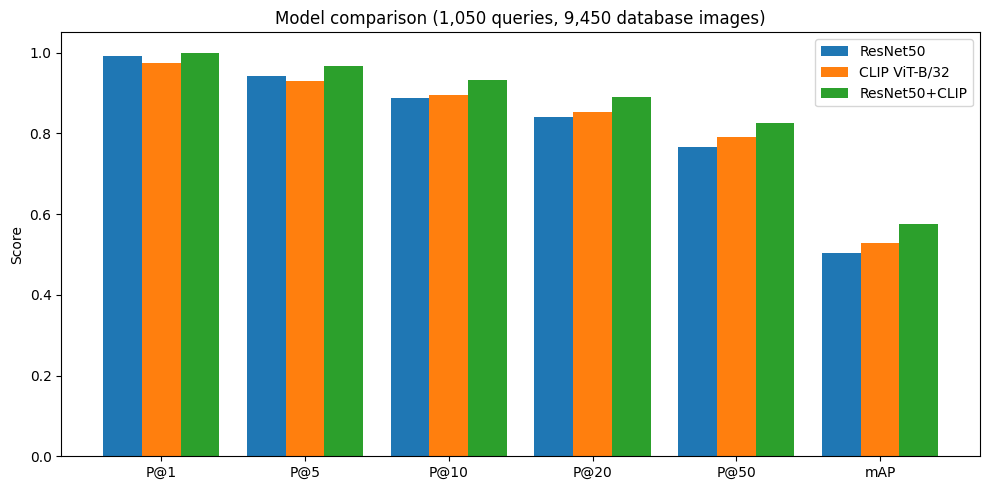

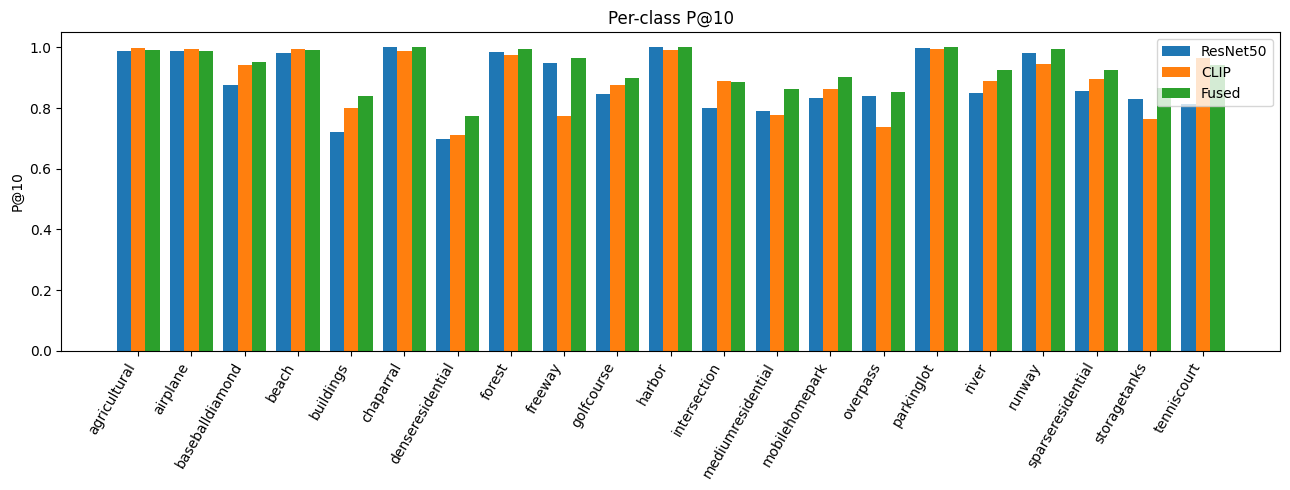

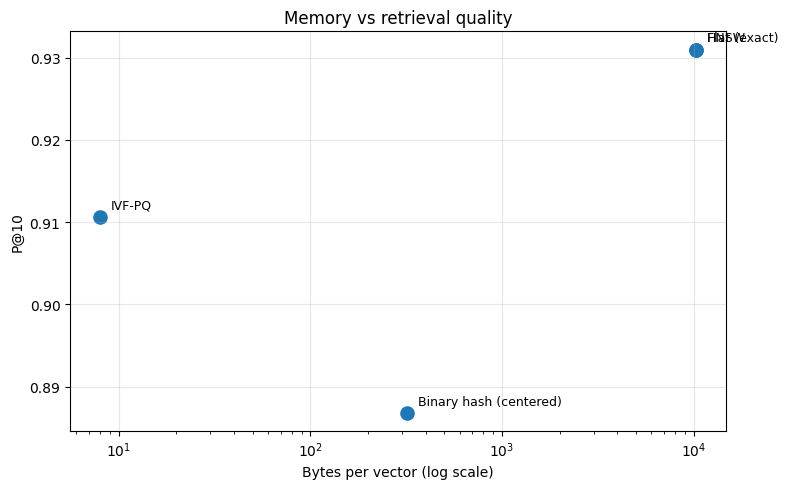

Saved to: /content/drive/MyDrive/cbir-eo/results
['model_comparison.csv', 'per_class_p10.csv', 'fusion_weight_sweep.csv', 'index_comparison.csv', 'plot_model_comparison.png', 'plot_per_class_p10.png', 'plot_memory_vs_quality.png']


In [28]:
import os
import matplotlib.pyplot as plt

out = "/content/drive/MyDrive/cbir-eo/results"
os.makedirs(out, exist_ok=True)

# ---------- 1. Model comparison table ----------
df_models = pd.DataFrame([res_resnet, res_clip, res_fused])
df_models.to_csv(f"{out}/model_comparison.csv", index=False)

# ---------- 2. Per-class P@10 table ----------
df_class = pd.DataFrame({
    "class": classes,
    "ResNet50": [rel_resnet[q_labels == c, :10].mean() for c in range(len(classes))],
    "CLIP":     [rel_clip[q_labels == c, :10].mean()   for c in range(len(classes))],
    "Fused":    [rel_fused[q_labels == c, :10].mean()  for c in range(len(classes))],
}).round(4)
df_class.to_csv(f"{out}/per_class_p10.csv", index=False)

# ---------- 3. Fusion weight sweep ----------
sweep = []
for w in [0.3, 0.4, 0.5, 0.6, 0.7]:
    f = np.concatenate([np.sqrt(w) * feats, np.sqrt(1 - w) * clip_feats], axis=1).astype("float32")
    r, _ = evaluate(f, f"w={w}")
    sweep.append({"w_resnet": w, "P@10": r["P@10"], "mAP": r["mAP"]})
df_sweep = pd.DataFrame(sweep)
df_sweep.to_csv(f"{out}/fusion_weight_sweep.csv", index=False)

# ---------- 4. Index comparison table ----------
df_idx = pd.DataFrame(res).copy()
df_idx["bytes/vector"] = [d * 4, d * 4, 8, codes.shape[1]]
df_idx["recall@100 vs exact"] = [
    1.0,
    round(recall100(hnsw.search(qf, 100)[1]), 4),
    round(recall100(ivfpq.search(qf, 100)[1]), 4),
    round(recall100(bin_index.search(codes[query_idx], 100)[1]), 4),
]
df_idx.to_csv(f"{out}/index_comparison.csv", index=False)

# ---------- Plot 1: model comparison ----------
metrics_cols = ["P@1", "P@5", "P@10", "P@20", "P@50", "mAP"]
x = np.arange(len(metrics_cols)); bw = 0.27
fig, ax = plt.subplots(figsize=(10, 5))
for i, (name, row) in enumerate(zip(df_models["model"], df_models.to_dict("records"))):
    ax.bar(x + (i - 1) * bw, [row[m] for m in metrics_cols], bw, label=name)
ax.set_xticks(x); ax.set_xticklabels(metrics_cols)
ax.set_ylabel("Score"); ax.set_ylim(0, 1.05)
ax.set_title("Model comparison (1,050 queries, 9,450 database images)")
ax.legend(); plt.tight_layout()
plt.savefig(f"{out}/plot_model_comparison.png", dpi=200); plt.show()

# ---------- Plot 2: per-class P@10 ----------
fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(classes))
for i, col in enumerate(["ResNet50", "CLIP", "Fused"]):
    ax.bar(x + (i - 1) * bw, df_class[col], bw, label=col)
ax.set_xticks(x); ax.set_xticklabels(classes, rotation=60, ha="right")
ax.set_ylabel("P@10"); ax.set_ylim(0, 1.05)
ax.set_title("Per-class P@10"); ax.legend(); plt.tight_layout()
plt.savefig(f"{out}/plot_per_class_p10.png", dpi=200); plt.show()

# ---------- Plot 3: memory vs quality ----------
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df_idx["bytes/vector"], df_idx["P@10"], s=90)
for _, r in df_idx.iterrows():
    ax.annotate(r["index"], (r["bytes/vector"], r["P@10"]),
                textcoords="offset points", xytext=(8, 6), fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("Bytes per vector (log scale)"); ax.set_ylabel("P@10")
ax.set_title("Memory vs retrieval quality")
ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f"{out}/plot_memory_vs_quality.png", dpi=200); plt.show()

print("Saved to:", out)
print(os.listdir(out))

In [31]:
import sys, os
from importlib.metadata import version, PackageNotFoundError
import torch

proj = "/content/drive/MyDrive/cbir-eo"
os.makedirs(proj, exist_ok=True)

# ---------- requirements.txt ----------
pkgs = ["torch", "torchvision", "open_clip_torch", "faiss-cpu",
        "numpy", "pandas", "pillow", "matplotlib"]
lines = []
for p in pkgs:
    try:
        lines.append(f"{p}=={version(p)}")
    except PackageNotFoundError:
        print("Not found:", p)
req = "\n".join(lines) + "\n"
open(f"{proj}/requirements.txt", "w").write(req)
print(req)

gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only"
py = sys.version.split()[0]
print("Python:", py, "| GPU:", gpu)

# ---------- README.md (built line by line) ----------
FENCE = "`" * 3
R = []
R.append("# Content-Based Satellite Image Retrieval (UCMerced Land Use)")
R.append("")
R.append("Project for the Information Retrieval course (A.Y. 2025/2026), task: Content-Based Image Retrieval (CBIR).")
R.append("")
R.append("## What the project does")
R.append("Given a query satellite image, the system retrieves the most similar images from a database.")
R.append("It compares two pretrained feature extractors (ResNet50, CLIP ViT-B/32), a fusion of both,")
R.append("and four FAISS indexes (exact, HNSW, IVF-PQ, binary hash codes).")
R.append("Relevance is defined by the land-use class label.")
R.append("")
R.append("## Environment")
R.append(f"- Python: {py}")
R.append(f"- GPU: {gpu} (Google Colab)")
R.append("- Libraries: see `requirements.txt`")
R.append("")
R.append(FENCE)
R.append("pip install -r requirements.txt")
R.append(FENCE)
R.append("")
R.append("## Dataset (not included, about 2 GB)")
R.append("Kaggle version of UCMerced Land Use: https://www.kaggle.com/datasets/apollo2506/landuse-scene-classification")
R.append("")
R.append("This version has 21 classes with 500 images each (10,500 total), which differs from the")
R.append("standard 2,100-image benchmark. Only the folder `images/` is used. Download and unzip it so that")
R.append("the path is `/content/ucmerced/images/<class_name>/*.png` (or change `root` in the notebook).")
R.append("")
R.append("Download inside Colab (needs a Kaggle API token):")
R.append(FENCE)
R.append("!kaggle datasets download -d apollo2506/landuse-scene-classification -p /content")
R.append("!unzip -q /content/landuse-scene-classification.zip -d /content/ucmerced")
R.append(FENCE)
R.append("")
R.append("## How to run")
R.append("1. Open `notebooks/cbir_pipeline.ipynb` in Google Colab (GPU runtime recommended).")
R.append("2. Install the requirements and download the dataset as above.")
R.append("3. Run the cells in order. The notebook:")
R.append("   - checks for near-duplicate images,")
R.append("   - extracts ResNet50 and CLIP embeddings (L2-normalized),")
R.append("   - splits the data (seed 42): 50 queries and 450 database images per class")
R.append("     (1,050 queries, 9,450 database images),")
R.append("   - evaluates P@k and mAP,")
R.append("   - fuses the two models by weighted concatenation (w = 0.5),")
R.append("   - compares FAISS indexes and saves tables and plots to `results/`.")
R.append("")
R.append("## Main results (single random split)")
R.append("| Model | P@1 | P@10 | mAP (full ranking) |")
R.append("|---|---|---|---|")
R.append("| ResNet50 | 0.9914 | 0.8872 | 0.5046 |")
R.append("| CLIP ViT-B/32 | 0.9733 | 0.8939 | 0.5283 |")
R.append("| Fused (w = 0.5) | 0.9981 | 0.9310 | 0.5748 |")
R.append("")
R.append("| Index | P@10 | Top-10 overlap with exact | Recall@100 vs exact | Bytes per vector |")
R.append("|---|---|---|---|---|")
R.append("| Flat (exact) | 0.9310 | n/a | 1.0 | 10,240 |")
R.append("| HNSW | 0.9310 | 1.00 | 0.9999 | 10,240 |")
R.append("| IVF-PQ | 0.9106 | 0.70 | 0.7863 | 8 |")
R.append("| Binary hash | 0.8868 | 0.53 | 0.4991 | 320 |")
R.append("")
R.append("## Limitations")
R.append("- One random split only; small differences are not statistically established.")
R.append("- Fusion weights were explored on the evaluation queries, so tuned values are slightly optimistic.")
R.append("- Results are not comparable with published numbers (different dataset version and split).")
R.append("- Timings at this scale are noisy and are not used for conclusions.")
R.append("- Relevance is defined only by class label.")
R.append("")
R.append("## Repository structure")
R.append(FENCE)
R.append("notebooks/cbir_pipeline.ipynb   main notebook with outputs")
R.append("results/                        CSV tables and PNG plots")
R.append("requirements.txt                library versions")
R.append("README.md                       this file")
R.append(FENCE)

open(f"{proj}/README.md", "w").write("\n".join(R) + "\n")
print("Saved:", [f for f in os.listdir(proj) if f.endswith((".txt", ".md"))])

torch==2.11.0+cu130
torchvision==0.26.0+cu130
open_clip_torch==3.3.0
faiss-cpu==1.15.1
numpy==2.4.6
pandas==2.2.3
pillow==11.3.0
matplotlib==3.10.0

Python: 3.13.16 | GPU: Tesla T4
Saved: ['requirements.txt', 'README.md']


In [32]:
proj = "/content/drive/MyDrive/cbir-eo"
req = open(f"{proj}/requirements.txt").read()
req = req.replace("+cu130", "")
open(f"{proj}/requirements.txt", "w").write(req)
print(req)

torch==2.11.0
torchvision==0.26.0
open_clip_torch==3.3.0
faiss-cpu==1.15.1
numpy==2.4.6
pandas==2.2.3
pillow==11.3.0
matplotlib==3.10.0



In [33]:
proj = "/content/drive/MyDrive/cbir-eo"
p = f"{proj}/README.md"
t = open(p).read().replace("| 0.7863 | 8 |", "| 0.7863 | 64 |")
open(p, "w").write(t)

c = f"{proj}/results/index_comparison.csv"
df = pd.read_csv(c)
df.loc[df["index"] == "IVF-PQ", "bytes/vector"] = 64
df.to_csv(c, index=False)
print(df[["index", "bytes/vector"]])

                    index  bytes/vector
0            Flat (exact)         10240
1                    HNSW         10240
2                  IVF-PQ            64
3  Binary hash (centered)           320
